In [1]:
import pandas as pd
import plotly.express as px
import kaleido
kaleido.get_chrome_sync()

WindowsPath('C:/Users/MarcelaVazquez/AppData/Local/plotly/choreographer/deps/chrome-win64/chrome.exe')

In [2]:
import plotly.io as pio
import plotly.graph_objects as go

INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

COLORS = {
    "All Nationalities": INK2, "British": BLUE, "EU+": ORANGE, "Non-EU+": AQUA,
    "EU": ORANGE, "Non EU": AQUA,
    "Main Applicant": BLUE, "Dependant": ORANGE,
    "Current rules": BLUE, "Proposed rules": ORANGE,
    "Current (5 years)": BLUE, "Proposed 10 year rule": ORANGE,
}

# Layer 1: light style for every chart in the notebook
pio.templates["immig"] = go.layout.Template(layout=dict(
    font=dict(family="Segoe UI, Arial, sans-serif", color=INK),
    paper_bgcolor=SURFACE, plot_bgcolor=SURFACE,
    colorway=[BLUE, ORANGE, AQUA],
    xaxis=dict(showgrid=False, linecolor=AXIS, tickfont=dict(color=MUTED), title_font=dict(color=INK2)),
    yaxis=dict(gridcolor=GRID, zerolinecolor=AXIS, tickfont=dict(color=MUTED), title_font=dict(color=INK2)),
    legend=dict(title_text=""),
    bargap=0.25,
))
pio.templates.default = "plotly_white+immig"

# Layer 2: only for the LinkedIn charts
def finish(fig, title, subtitle, source, name):
    fig.update_layout(
        width=1080, height=1350,
        font=dict(size=22),
        margin=dict(l=90, r=40, t=220, b=170),
        legend=dict(orientation="h", x=0, y=1.02, yanchor="bottom"),
        title=dict(text=f"<b>{title}</b><br><span style='font-size:22px;color:{INK2}'>{subtitle}</span>",
                   x=0.02, xanchor="left", font=dict(size=32)),
    )
    for tr in fig.data:
        if tr.name in COLORS:
            if tr.type == "bar":
                tr.marker.color = COLORS[tr.name]
            else:
                tr.line.color = COLORS[tr.name]
    fig.update_traces(marker_line_color=SURFACE, marker_line_width=2, selector=dict(type="bar"))
    fig.update_traces(line_width=3, marker_size=9, selector=dict(type="scatter"))
    fig.add_annotation(text=source, xref="paper", yref="paper", x=0, y=-0.16,
                       xanchor="left", yanchor="top", showarrow=False, align="left",
                       font=dict(size=16, color=MUTED))
    fig.write_image(f"../outputs/{name}.png", scale=2)
    return fig

In [3]:
df = pd.read_excel(
    "../data/raw/entry-clearance-visa-outcomes-datasets-jun-2026.xlsx",
    sheet_name="Data_Vis_D02",
    skiprows=3,
)
df.to_parquet("../data/processed/vis_d02.parquet")  # load this from now on, much faster

In [4]:
df.head()

,Year,Quarter,Nationality,Region,Visa type group,Visa type,Visa type subgroup,Applicant type,Case outcome,Decisions
0,2005,2005 Q1,Afghanistan,Asia Central,Family,Family: Child,Family: Child (for immediate settlement),All,Issued,2
1,2005,2005 Q1,Afghanistan,Asia Central,Family,Family: Child,Family: Child (for immediate settlement),All,Refused,4
2,2005,2005 Q1,Afghanistan,Asia Central,Family,Family: Other,Family: Other (for immediate settlement),All,Issued,5
3,2005,2005 Q1,Afghanistan,Asia Central,Family,Family: Other,Family: Other (for immediate settlement),All,Refused,23
4,2005,2005 Q1,Afghanistan,Asia Central,Family,Family: Partner,Family: Partner,All,Issued,103


In [5]:
df['Case outcome'].unique()

array(['Issued', 'Refused', 'Withdrawn', 'Lapsed'], dtype=object)

In [6]:
df['Applicant type'].unique()

array(['All', 'Dependant', 'Main Applicant'], dtype=object)

In [7]:
df['Quarter'].min()

'2005 Q1'

In [8]:
df['Quarter'].max()

'2026 Q2'

In [9]:
grants = df[(df["Case outcome"] == "Issued") & (df["Visa type group"] != "Visitor")]

yearly = (
    grants.groupby(["Year", "Visa type group"])["Decisions"]
    .sum()
    .unstack()
)
yearly

Visa type group,Family,Other,Study,Work
Year,,,,
2005,66343,124084,207418,243424
2006,70155,123524,234329,249603
2007,64427,118840,246196,205790
2008,53584,104875,274213,184647
2009,49212,84878,341064,155647
2010,52361,79261,334735,160724
2011,45041,74942,323276,149310
2012,40231,70784,278100,145110
2013,33133,73561,296226,154760


In [10]:
recent = grants[grants["Year"].between(2021, 2025)]

by_type = (
    recent.groupby(["Year", "Visa type group", "Visa type"])["Decisions"]
    .sum()
    .unstack("Year")
)
by_type

Year                                                           2021      2022  \
Visa type group Visa type                                                       
Family          Family: Child                                5785.0    6362.0   
                Family: Other                                 328.0     313.0   
                Family: Partner                             30382.0   36326.0   
                Refugee Family Reunion                       5687.0    4118.0   
Other           BN(O) route                                 75579.0   53694.0   
                Dep. joining or accompanying                 8921.0    5007.0   
                EEA Family Permit                            6528.0      26.0   
                EU Settlement Scheme permits                55275.0   32209.0   
                Other settlement visas                       2506.0    3838.0   
                Other temporary visas                       32674.0   30673.0   
                Ukraine Visa Schemes                            NaN  209706.0   
Study           Other study                                  4625.0    4987.0   
                Sponsored study                            430485.0  618711.0   
Work            Investor, business development and talent    5919.0    7257.0   
                Other work visas and exemptions             28716.0   28823.0   
                Temporary Worker                            53919.0   72436.0   
                Worker                                     150639.0  313049.0   

Year                                                           2023      2024  \
Visa type group Visa type                                                       
Family          Family: Child                                9646.0    9235.0   
                Family: Other                                 469.0     699.0   
                Family: Partner                             60648.0   55969.0   
                Refugee Family Reunion                       9320.0   19258.0   
Other           BN(O) route                                 28168.0   19139.0   
                Dep. joining or accompanying                 4362.0    3835.0   
                EEA Family Permit                              90.0       2.0   
                EU Settlement Scheme permits                17283.0   13501.0   
                Other settlement visas                       5016.0    3416.0   
                Other temporary visas                       39302.0   37981.0   
                Ukraine Visa Schemes                        40287.0   17826.0   
Study           Other study                                  4229.0    4201.0   
                Sponsored study                            600024.0  414731.0   
Work            Investor, business development and talent    9574.0    7355.0   
                Other work visas and exemptions             28815.0   27011.0   
                Temporary Worker                            77034.0   80409.0   
                Worker                                     498204.0  253364.0   

Year                                                           2025  
Visa type group Visa type                                            
Family          Family: Child                                6647.0  
                Family: Other                                 364.0  
                Family: Partner                             40383.0  
                Refugee Family Reunion                      18577.0  
Other           BN(O) route                                  8925.0  
                Dep. joining or accompanying                 3314.0  
                EEA Family Permit                               1.0  
                EU Settlement Scheme permits                 7710.0  
                Other settlement visas                       2730.0  
                Other temporary visas                       34668.0  
                Ukraine Visa Schemes                        14895.0  
Study     

In [11]:
deps = (
    recent[recent["Visa type group"].isin(["Study", "Work"])]
    .groupby(["Year", "Visa type group", "Applicant type"])["Decisions"]
    .sum()
    .unstack("Applicant type")
)
deps

Applicant type        Dependant  Main Applicant
Year Visa type group                           
2021 Study                54486          380624
     Work                 75677          163516
2022 Study               134571          489127
     Work                154783          266782
2023 Study               143276          460977
     Work                277620          336007
2024 Study                21899          397033
     Work                158871          209268
2025 Study                19553          407787
     Work                 92412          168018

In [12]:
worker = recent[recent["Visa type"] == "Worker"]

worker_split = (
    worker.groupby(["Year", "Visa type subgroup", "Applicant type"])["Decisions"]
    .sum()
    .unstack(["Applicant type"])
)
worker_split

Applicant type                                           Dependant  \
Year Visa type subgroup                                              
2021 Health and Care Worker                                31491.0   
     International Sportsperson                               23.0   
     Intra-company Transfer                                12608.0   
     Minister of Religion (previously Tier 2)                  NaN   
     Skilled Worker                                        23697.0   
     Sportsperson (previously Tier 2)                          NaN   
     Tier 2 - Dependant                                      935.0   
     Tier 2 - General                                          NaN   
     Tier 2 - Intra-company Transfer                           NaN   
     Tier 2 - Intra-company Transfer (Long-term Staff)       491.0   
     Tier 2 - Intra-company Transfer (Short-term Staff)       16.0   
2022 Dependant - Global Business Mobility                  12407.0   
     Health and Care Worker                                80912.0   
     International Sportsperson                              318.0   
     Intra-company Transfer                                 7030.0   
     Minister of Religion (previously Tier 2)                  NaN   
     Senior or Specialist Worker (Global Business Mo...        NaN   
     Skilled Worker                                        46020.0   
     Tier 2 - Dependant                                      414.0   
     Tier 2 - General                                          NaN   
     Tier 2 - Intra-company Transfer                           NaN   
     Tier 2 - Intra-company Transfer (Long-term Staff)        24.0   
     Tier 2 - Intra-company Transfer (Short-term Staff)        2.0   
2023 Dependant - Global Business Mobility                  13974.0   
     Health and Care Worker                               202334.0   
     International Sportsperson                              320.0   
     Intra-company Transfer                                   29.0   
     Minister of Religion (previously Tier 2)                  NaN   
     Scale-up Worker                                          32.0   
     Senior or Specialist Worker (Global Business Mo...        NaN   
     Skilled Worker                                        51754.0   
     Tier 2 - Dependant                                      475.0   
     Tier 2 - General                                          NaN   
     Tier 2 - Intra-company Transfer (Long-term Staff)         1.0   
2024 Dependant - Global Business Mobility                  10434.0   
     Health and Care Worker                                83426.0   
     International Sportsperson                              469.0   
     Intra-company Transfer                                    3.0   
     Minister of Religion (previously Tier 2)                  NaN   
     Scale-up Worker                                          46.0   
     Senior or Specialist Worker (Global Business Mo...        NaN   
     Skilled Worker                                        57154.0   
     Tier 2 - Dependant                                      593.0   
     Tier 2 - General                                          NaN   
     Tier 2 - Intra-company Transfer (Long-term Staff)         1.0   
2025 Dependant - Global Business Mobility                   9274.0   
     Health and Care Worker                                35339.0   
     International Sportsperson                              529.0   
     Minister of Religion (previously Tier 2)                  NaN   
     Scale-up Worker                                          69.0   
     Senior or Specialist Worker (Global Business Mo...        NaN   
     Skilled Worker                                        40656.0   
     Tier 2 - Dependant                                      635.0   

Applicant type                                           Main Applicant  
Year Visa type subgroup                                                  
2

In [13]:
worker_map = {
    "Health and Care Worker": "Health and Care",
    "Skilled Worker": "Skilled Worker",
    "Tier 2 - General": "Skilled Worker",
    "Tier 2 - Dependant": "Skilled Worker",
    "Minister of Religion (previously Tier 2)": "Other",
    "Sportsperson (previously Tier 2)": "Other",
    "International Sportsperson": "Other",
    "Scale-up Worker": "Other",
}
# Anything with Intra-company or Global Business Mobility in the name
worker = worker.copy()
worker["Worker group"] = worker["Visa type subgroup"].map(worker_map)
mask = worker["Visa type subgroup"].str.contains("Intra-company|Global Business Mobility")
worker.loc[mask, "Worker group"] = "Business transfers"

worker["Worker group"].isna().sum()  # should be 0

0

In [14]:
# Chart 1: main applicants vs dependants by worker group
worker_long = (
    worker.groupby(["Year", "Worker group", "Applicant type"])["Decisions"]
    .sum()
    .reset_index()
)

fig = px.bar(
    worker_long,
    x="Year", y="Decisions",
    color="Applicant type",
    facet_col="Worker group",
    title="Work visas granted: main applicants vs dependants, 2021 to 2025",
)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

In [15]:
# Chart 2: study and work dependants, with the 2024 bans marked
deps_long = deps.stack().reset_index(name="Decisions")
fig = px.line(
    deps_long,
    x="Year", y="Decisions",
    color="Applicant type",
    facet_col="Visa type group",
    markers=True,
    title="Study and work visas: main applicants vs dependants",
    color_discrete_map={"Dependant": "#636EFA", "Main Applicant": "#EF553B"},
)
fig.update_xaxes(dtick=1, tickformat="d")
fig.add_vline(x=2024, line_dash="dot")
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

In [16]:
ons_path = "../data/raw/may2026publicationspreadsheet.xlsx"
pd.ExcelFile(ons_path).sheet_names

['Cover Sheet',
 'Contents',
 'Definitions',
 'Notes',
 '1',
 '2',
 '3a',
 '3b',
 '3c',
 '3d',
 '3e',
 '3f',
 '4a',
 '4b',
 '5',
 '6a',
 '6b',
 '7a',
 '7b',
 '7c',
 '7d',
 '8',
 '9']

In [17]:
contents = pd.read_excel(ons_path, sheet_name="Contents")
pd.set_option("display.max_colwidth", None)
contents

,Contents,Unnamed: 1
0,This worksheet contains one table.,NaN
1,Worksheet,Table title
2,1,"Table 1: Long-term international migration into and out of the United Kingdom by nationality, using new approach to producing migration estimates"
3,2,"Table 2: Long-term international migration into and out of the United Kingdom measures of uncertainty, using new approach to producing migration estimates"
4,3a,"Table 3a: Long-term international immigration to the UK among the top ten highest contributing EU+ visa holder nationalities as of YE December 2025, by reason for immigration,"
5,3b,"Table 3b: Long-term international emigration from the UK among the top ten highest contributing EU+ visa holder nationalities as of YE December 2025, by reason for immigration, using new approach to producing migration estimates"
6,3c,"Table 3c: Long-term international immigration to the UK among the top ten highest contributing EU settled status nationalities as of YE December 2025, using new approach to producing migration estimates"
7,3d,"Table 3d: Long-term international emigration from the UK among the top ten highest contributing EU settled status nationalities as of YE December 2025, using new approach to producing migration estimates"
8,3e,"Table 3e: Long-term international immigration to the UK among the top ten highest contributing non-EU+ nationalities as of YE December 2025, by reason for immigration, using new approach to producing migration estimates"
9,3f,"Table 3f: Long-term international emigration to the UK among the top ten highest contributing non-EU+ nationalities as of YE December 2025, by original reason for immigration, using new approach to producing migration estimates"


In [18]:
t1 = pd.read_excel(ons_path, sheet_name="1", skiprows=5)

t1.columns = (
    t1.columns
    .str.replace(r"\n?\[.*?\]", "", regex=True)
    .str.strip()
)
t1.columns

Index(['Flow', 'Period', 'All Nationalities', 'British', 'EU+', 'Non-EU+'], dtype='object')

In [19]:
t1["Period"].unique()[-8:]
t1["Flow"].unique()
t1.dtypes
print(t1["Period"].unique()[-8:])
print(t1["Flow"].unique())

['YE Mar 24' 'YE Jun 24' 'YE Sep 24 R' 'YE Dec 24 R' 'YE Mar 25 P R'
 'YE Jun 25 P R' 'YE Sep 25 P' 'YE Dec 25 P']
['Immigration' 'Emigration' 'Net migration']


In [20]:
# Flag provisional and revised periods
t1["Provisional"] = t1["Period"].str.contains(r"\bP\b")
t1["Revised"] = t1["Period"].str.contains(r"\bR\b")

# Keep just "YE Mon YY", then turn it into a real date
t1["Period_clean"] = t1["Period"].str.extract(r"^(YE \w{3} \d{2})")[0]
t1["Date"] = (
    pd.to_datetime(t1["Period_clean"].str[3:], format="%b %y")
    + pd.offsets.MonthEnd(0)
)

t1[["Period", "Date", "Provisional", "Revised"]].tail(8)

,Period,Date,Provisional,Revised
157,YE Mar 24,2024-03-31,False,False
158,YE Jun 24,2024-06-30,False,False
159,YE Sep 24 R,2024-09-30,False,True
160,YE Dec 24 R,2024-12-31,False,True
161,YE Mar 25 P R,2025-03-31,True,True
162,YE Jun 25 P R,2025-06-30,True,True
163,YE Sep 25 P,2025-09-30,True,False
164,YE Dec 25 P,2025-12-31,True,False


In [21]:
net = t1[t1["Flow"] == "Net migration"].melt(
    id_vars=["Date", "Provisional"],
    value_vars=["All Nationalities", "British", "EU+", "Non-EU+"],
    var_name="Nationality",
    value_name="People",
)

fig = px.line(net, x="Date", y="People", color="Nationality",
              title="UK net migration by nationality, rolling 12 months")
fig.add_hline(y=0, line_color="grey")
fig.show()

In [22]:
first_p = t1.loc[t1["Provisional"], "Date"].min()
fig.add_vrect(x0=first_p, x1=t1["Date"].max(),
              fillcolor="grey", opacity=0.15, line_width=0,
              annotation_text="Provisional", annotation_position="top left")

events = {
    "2016-06-23": "Brexit vote",
    "2021-01-01": "End of free movement",
    "2024-03-11": "Dependant bans",
}
for date, label in events.items():
    fig.add_vline(x=pd.Timestamp(date).timestamp() * 1000, line_dash="dot", line_color="grey")
    fig.add_annotation(x=date, y=1.05, yref="paper", text=label, showarrow=False, font_size=10)
fig.show()

In [23]:
t4b_raw = pd.read_excel(ons_path, sheet_name="4b", header=None)
t4b_raw.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,"Table 4b: Long-term international immigration, emigration and net migration of non-EU+ nationals by reason,",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"using new approach to producing migration estimates [definition 4] [notes 7, 8 and 17]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,This worksheet contains one table,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Notes and definitions are referred to in this table. The text for these can be found in the corresponding worksheets.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"Some shorthand is used in this table, P = provisional, R = revised, YE = Year Ending, BNO = British National (Overseas)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Flow\n[note 2],Period\n[note 10],All reasons\n[note 5],All Work Related,Work: Main applicant,Work: Dependant,All Study Related,Study: Main applicant,Study: Dependant,Family,All Humanitarian,Humanitarian: BNO\n[definition 8],Humanitarian:\nResettlement\n[definition 9],Humanitarian:\nUkraine\n[definition 10],Asylum\n[definition 11],Other\n[definition 13]
6,Immigration,YE Jun 19,347000,89000,56000,33000,126000,119000,7000,65000,6000,0,6000,0,39000,22000
7,Immigration,YE Sep 19,351000,95000,59000,35000,116000,109000,8000,71000,6000,0,6000,0,41000,22000
8,Immigration,YE Dec 19,368000,99000,62000,37000,120000,112000,9000,78000,6000,0,6000,0,42000,23000
9,Immigration,YE Mar 20,388000,102000,63000,39000,135000,124000,11000,82000,5000,0,5000,0,42000,23000


In [24]:
def load_ons_table(path, sheet, skiprows=5):
    df = pd.read_excel(path, sheet_name=sheet, skiprows=skiprows)

    # Remove [note x] references and line breaks from column names
    df.columns = (
        df.columns
        .str.replace(r"\n?\[.*?\]", "", regex=True)
        .str.replace("\n", " ")
        .str.strip()
    )

    # Flag provisional and revised periods, then turn Period into a date
    df["Provisional"] = df["Period"].str.contains(r"\bP\b")
    df["Revised"] = df["Period"].str.contains(r"\bR\b")
    period = df["Period"].str.extract(r"^(YE \w{3} \d{2})")[0]
    df["Date"] = (
        pd.to_datetime(period.str[3:], format="%b %y")
        + pd.offsets.MonthEnd(0)
    )
    return df

In [25]:
t4b = load_ons_table(ons_path, "4b")
t4b.columns

Index(['Flow', 'Period', 'All reasons', 'All Work Related',
       'Work: Main applicant', 'Work: Dependant', 'All Study Related',
       'Study: Main applicant', 'Study: Dependant', 'Family',
       'All Humanitarian', 'Humanitarian: BNO', 'Humanitarian: Resettlement',
       'Humanitarian: Ukraine', 'Asylum', 'Other', 'Provisional', 'Revised',
       'Date'],
      dtype='object')

In [26]:
reasons = ["All Work Related", "All Study Related", "Family",
           "All Humanitarian", "Asylum", "Other"]

check = t4b[reasons].sum(axis=1)
(t4b["All reasons"] - check).abs().max()

2000

In [27]:
net4b = t4b[t4b["Flow"] == "Net migration"].melt(
    id_vars=["Date"], value_vars=reasons,
    var_name="Reason", value_name="People",
)

fig = px.line(net4b, x="Date", y="People", color="Reason",
              title="Non EU+ net migration by reason, rolling 12 months")
fig.add_hline(y=0, line_color="grey")
fig.show()

In [28]:
study = t4b[t4b["Flow"].isin(["Immigration", "Emigration"])]

fig = px.line(study, x="Date", y="All Study Related", color="Flow",
              title="Non EU+ study: arrivals vs departures, rolling 12 months")
fig.update_traces(fill="tonexty", selector=dict(name="Emigration"))
fig.show()

In [29]:
mj_path = "../data/raw/migrant-journey-detailed-datasets-2025.xlsx"
print(pd.ExcelFile(mj_path).sheet_names)

mj_raw = pd.read_excel(mj_path, sheet_name="MJ_D01", header=None)
mj_raw.head(15)

['Cover_sheet', 'Contents', 'Notes', 'List of fields', 'MJ_D01', 'Data - MJ_D01 ', 'MJ_D02', 'Data - MJ_D02']


,0,1,2,3,4
0,End of year leave category and immigration status by year of initial grant and leave type,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN
4,Year of initial leave,2020,NaN,NaN,NaN
5,Year,2025,NaN,NaN,NaN
6,Region,(All),NaN,NaN,NaN
7,Nationality,(All),NaN,NaN,NaN
8,Applicant type,(All),NaN,NaN,NaN
9,Years into journey,(All),NaN,NaN,NaN


In [30]:
mj_raw = pd.read_excel(mj_path, sheet_name="Data - MJ_D01 ", header=None)
mj_raw.head(10)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,End of year leave category and immigration status by year of initial grant and leave type - dataset,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Year of initial leave,Initial leave type group,Initial leave type,Initial leave subgroup,Applicant type,Region,Nationality,Year,Immigration Status at end of year,Leave type group at end of year,Leave type at end of year,Leave type at end of year subgroup,Years into journey,Journeys
2,2008,Asylum,Other Asylum,Other Asylum,Main applicant,Africa North,Algeria,2008,Expired,Expired,Expired,Expired,0 to 1 years,3
3,2008,Asylum,Other Asylum,Other Asylum,Main applicant,Africa North,Algeria,2008,Valid leave to remain,Asylum,Asylum applicant,Asylum applicant,0 to 1 years,31
4,2008,Asylum,Other Asylum,Other Asylum,Main applicant,Africa North,Algeria,2008,Valid leave to remain,Asylum,Other Asylum,Other Asylum,0 to 1 years,7
5,2008,Asylum,Other Asylum,Other Asylum,Main applicant,Africa North,Algeria,2009,Expired,Expired,Expired,Expired,1 to 2 years,5
6,2008,Asylum,Other Asylum,Other Asylum,Main applicant,Africa North,Algeria,2009,Valid leave to remain,Asylum,Asylum applicant,Asylum applicant,1 to 2 years,26
7,2008,Asylum,Other Asylum,Other Asylum,Main applicant,Africa North,Algeria,2009,Valid leave to remain,Asylum,Other Asylum,Other Asylum,1 to 2 years,10
8,2008,Asylum,Other Asylum,Other Asylum,Main applicant,Africa North,Algeria,2010,Expired,Expired,Expired,Expired,2 to 3 years,6
9,2008,Asylum,Other Asylum,Other Asylum,Main applicant,Africa North,Algeria,2010,Valid leave to remain,Asylum,Asylum applicant,Asylum applicant,2 to 3 years,26


In [31]:
mj = pd.read_excel(mj_path, sheet_name="Data - MJ_D01 ", skiprows=1)
mj.columns

Index(['Year of initial leave', 'Initial leave type group',
       'Initial leave type', 'Initial leave subgroup', 'Applicant type',
       'Region', 'Nationality', 'Year', 'Immigration Status at end of year',
       'Leave type group at end of year', 'Leave type at end of year',
       'Leave type at end of year subgroup', 'Years into journey', 'Journeys'],
      dtype='object')

In [32]:
print(mj["Initial leave type group"].unique())
print(mj["Initial leave type"].unique())
print(mj["Years into journey"].unique())

['Asylum' 'Dependants joining or accompanying' 'Family' 'Study' 'Work'
 'Safe and Legal' nan 'End of table']
['Other Asylum' 'Refugee and protection based leave'
 'Dependants joining or accompanying' 'Child' 'Other' 'Partner'
 'Refugee Family Reunion' 'Sponsored study'
 'Investor, business development and talent'
 'Other work visas and exemptions' 'Temporary Worker' 'Worker'
 'Other resettlement' 'Resettlement Scheme' 'BN(O) route'
 'Ukraine schemes' nan]
['0 to 1 years' '1 to 2 years' '2 to 3 years' '3 to 4 years'
 '4 to 5 years' '5 to 6 years' '6 to 7 years' '7 to 8 years'
 '8 to 9 years' '9 to 10 years' '10 to 11 years' '11 to 12 years'
 '12 to 13 years' '13 to 14 years' '14 to 15 years' '15 to 16 years'
 '16 to 17 years' '17 to 18 years' nan]


In [33]:
mj = mj[
    mj["Initial leave type group"].notna()
    & (mj["Initial leave type group"] != "End of table")
].copy()

mj["Years since start"] = mj["Year"].astype(int) - mj["Year of initial leave"].astype(int)

In [34]:
study = mj[mj["Initial leave type"] == "Sponsored study"]

status = (
    study.groupby(["Year of initial leave", "Years since start",
                   "Immigration Status at end of year"])["Journeys"]
    .sum()
    .unstack(fill_value=0)
)
status["Total"] = status.sum(axis=1)
status["Still here %"] = (
    (status["Valid leave to remain"] + status["Indefinite leave to remain"])
    / status["Total"] * 100
)

status.loc[(2020, 5)]

Immigration Status at end of year
Expired                       106274.000000
Indefinite leave to remain       282.000000
Valid leave to remain          72605.000000
Total                         179161.000000
Still here %                      40.682403
Name: (2020.0, 5), dtype: float64

In [35]:
mj["Year of initial leave"] = mj["Year of initial leave"].astype(int)

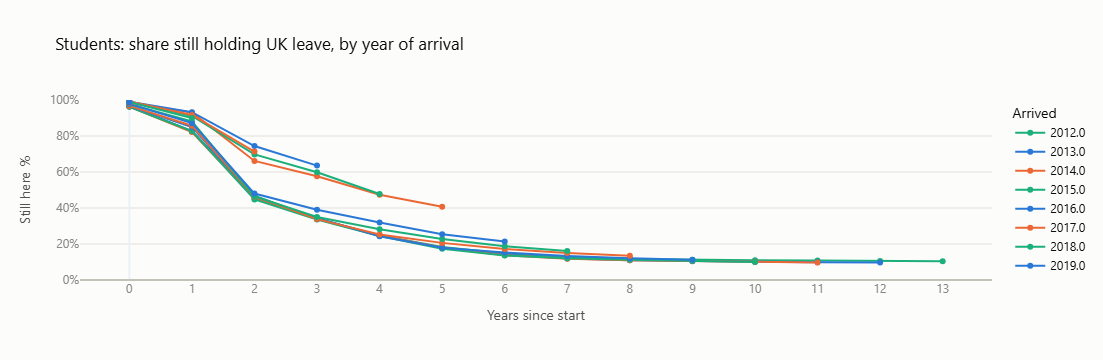

In [66]:
plot = status.reset_index()
plot = plot[plot["Year of initial leave"] >= 2012]
plot["Arrived"] = plot["Year of initial leave"].astype(str)

grey = {str(y): "lightgrey" for y in range(2012, 2020)}

fig = px.line(
    plot, x="Years since start", y="Still here %", color="Arrived",
    markers=True, color_discrete_map=grey,
    title="Students: share still holding UK leave, by year of arrival",
)
fig.update_xaxes(dtick=1)
fig.update_yaxes(range=[0, 100], ticksuffix="%")
fig.show()

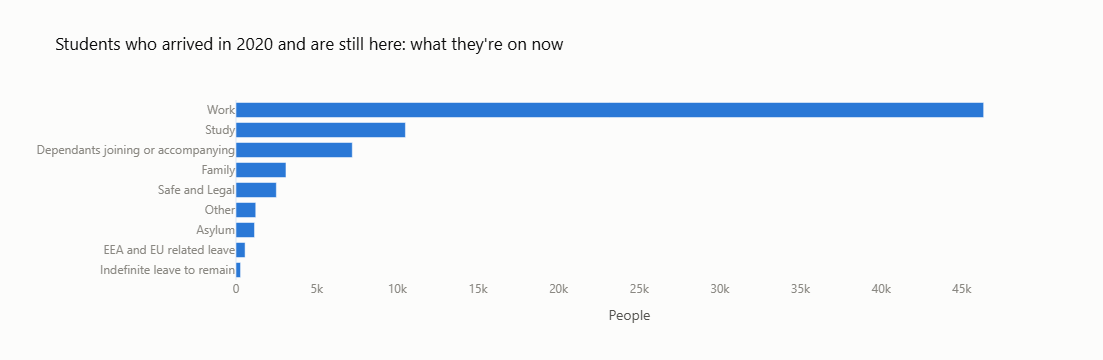

In [73]:
stayers = study[
    (study["Year of initial leave"] == 2020)
    & (study["Years since start"] == 5)
    & (study["Immigration Status at end of year"] != "Expired")
]

now_on = stayers.groupby("Leave type group at end of year")["Journeys"].sum().sort_values()

fig = px.bar(
    now_on, orientation="h",
    title="Students who arrived in 2020 and are still here: what they're on now",
)
fig.update_layout(showlegend=False, xaxis_title="People", yaxis_title="")
fig.show()

In [75]:
occ_path = "../data/raw/occupation-soc2020-visas-datasets-jun-2026.xlsx"
print(pd.ExcelFile(occ_path).sheet_names)

['Cover_Sheet', 'Contents', 'Notes', 'List_of_Fields', 'Occ_D01', 'Data_Occ_D01', 'Occ_D02', 'Data_Occ_D02']


In [77]:
occ_raw = pd.read_excel(occ_path, sheet_name="Data_Occ_D02", header=None)
occ_raw.head(10)

,0,1,2,3,4,5,6,7,8,9,10,11
0,"Grants of entry clearance visas, by occupation and industry, 2021 to 2026 Q2 - Dataset [Notes 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Link to notes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Link to contents,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Year,Quarter,Nationality,Region,Visa type,Visa type subgroup,Industry,Occ. major group,Occ. sub-major group,Occ. minor group,Occ. unit group,Grants
4,2021,2021 Q1,*,*,Worker,Health and Care Worker,Accommodation and Food Service Activities,2 - Professional Occupations,22 - Health Professionals,223 - Nursing Professionals,*,22
5,2021,2021 Q1,*,*,Worker,Health and Care Worker,Administrative and Support Service Activities,2 - Professional Occupations,22 - Health Professionals,223 - Nursing Professionals,*,8
6,2021,2021 Q1,*,*,Worker,Health and Care Worker,Education,3 - Associate Professional Occupations,"31 - Science, Engineering and Technology Associate Professionals","311 - Science, Engineering and Production Technicians",*,1
7,2021,2021 Q1,*,*,Worker,Health and Care Worker,Education,2 - Professional Occupations,22 - Health Professionals,222 - Therapy Professionals,*,2
8,2021,2021 Q1,*,*,Worker,Health and Care Worker,Education,2 - Professional Occupations,"21 - Science, Research, Engineering and Technology Professionals",211 - Natural and Social Science Professionals,*,1
9,2021,2021 Q1,*,*,Worker,Health and Care Worker,Education,2 - Professional Occupations,"21 - Science, Research, Engineering and Technology Professionals",216 - Research and Development (R&D) and Other Research Professionals,*,1


In [78]:
occ = pd.read_excel(occ_path, sheet_name="Data_Occ_D02", skiprows=3)
occ.dtypes

Year                     int64
Quarter                 object
Nationality             object
Region                  object
Visa type               object
Visa type subgroup      object
Industry                object
Occ. major group        object
Occ. sub-major group    object
Occ. minor group        object
Occ. unit group         object
Grants                   int64
dtype: object

In [79]:
(occ == "*").mean().round(2)

Year                    0.00
Quarter                 0.00
Nationality             0.26
Region                  0.26
Visa type               0.00
Visa type subgroup      0.00
Industry                0.00
Occ. major group        0.00
Occ. sub-major group    0.00
Occ. minor group        0.00
Occ. unit group         0.26
Grants                  0.00
dtype: float64

In [80]:
top = (
    occ.groupby(["Year", "Occ. minor group"])["Grants"]
    .sum()
    .reset_index()
)
top[top["Year"] == 2023].nlargest(15, "Grants")

,Year,Occ. minor group,Grants
269,2023,613 - Caring Personal Services,108099
215,2023,223 - Nursing Professionals,22894
254,2023,511 - Agricultural and Related Trades,16369
209,2023,213 - Information Technology Professionals,16116
287,2023,911 - Elementary Agricultural Occupations,16069
213,2023,221 - Medical Practitioners,9660
265,2023,543 - Food Preparation and Hospitality Trades,8984
237,2023,"341 - Artistic, Literary and Media Occupations",7051
208,2023,212 - Engineering Professionals,6823
221,2023,242 - Finance Professionals,6146


In [82]:
farm = occ[occ["Occ. minor group"].str.startswith(("511", "911")) & (occ["Year"] == 2023)]
farm.groupby("Visa type subgroup")["Grants"].sum()

Visa type subgroup
Charity Worker (previously Tier 5)                       11
Creative Worker                                           1
Government Authorised Exchange (previously Tier 5)       12
International Agreement (previously Tier 5)               1
International Sportsperson                               53
Religious Worker (previously Tier 5)                      2
Seasonal Worker (previously Tier 5)                   32068
Skilled Worker                                          290
Name: Grants, dtype: int64

In [83]:
total_2023 = top.loc[top["Year"] == 2023, "Grants"].sum()
health_care = top[
    (top["Year"] == 2023)
    & top["Occ. minor group"].str.startswith(("613", "223", "221", "225"))
]["Grants"].sum()

print(total_2023, health_care, round(health_care / total_2023 * 100, 1))

279501 143662 51.4


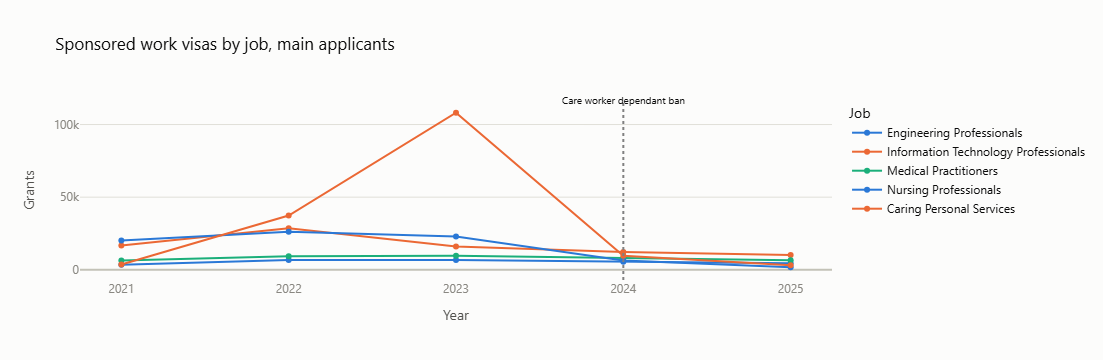

In [84]:
top_jobs = ["613", "223", "213", "221", "212"]
trend = top[top["Occ. minor group"].str.startswith(tuple(top_jobs))].copy()
trend = trend[trend["Year"] <= 2025]
trend["Job"] = trend["Occ. minor group"].str.split(" - ").str[1]

fig = px.line(trend, x="Year", y="Grants", color="Job", markers=True,
              title="Sponsored work visas by job, main applicants")
fig.update_xaxes(dtick=1)
fig.add_vline(x=2024, line_dash="dot", line_color="grey")
fig.add_annotation(x=2024, y=1.05, yref="paper", text="Care worker dependant ban",
                   showarrow=False, font_size=10)
fig.show()

In [91]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")

In [93]:
sfc = pd.read_csv("../data/manual/skills_for_care_2026.csv")
sfc_path = "../data/raw/Regional-area-data-download-2025-26.xlsx"
# Check 1: the Excel download agrees with the report for 2025/26
xl = pd.read_excel(sfc_path, sheet_name="Regional data 2025-26")
eng = xl[(xl["Area"] == "England")
         & (xl["Sector"] == "All sectors - LA, IND and DPR")
         & (xl["Service"] == "All services")
         & (xl["Job Role"] == "All job roles")]
print(eng[["Vacant posts", "Nationality - British count", "Nationality - Non EU count"]])

  Vacant posts Nationality - British count Nationality - Non EU count
0        96000                     1075000                     430000


In [94]:
# Check 2: your Home Office data vs the figure quoted in the report
fy = ["2023 Q2", "2023 Q3", "2023 Q4", "2024 Q1"]
care_fy = occ[(occ["Visa type subgroup"] == "Health and Care Worker")
              & occ["Occ. minor group"].str.startswith("613")
              & occ["Quarter"].isin(fy)]["Grants"].sum()
print(care_fy)

84715


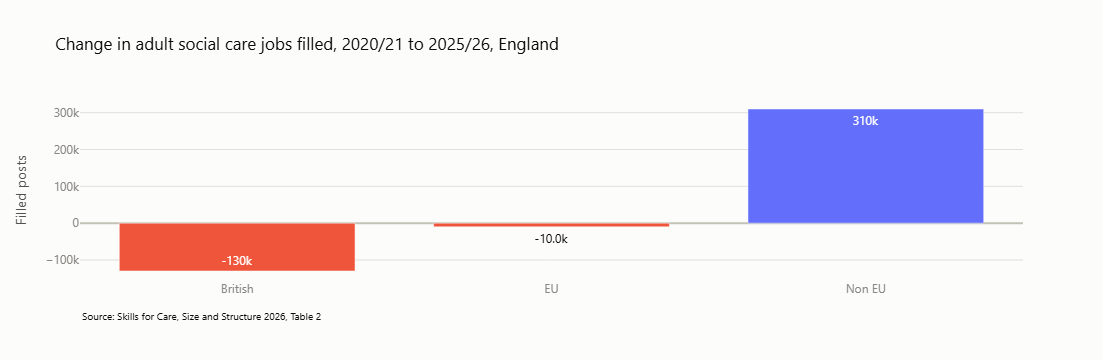

In [105]:
fig = px.bar(change, text_auto=".3s",
             color=change.values > 0,
             color_discrete_map={True: "#636EFA", False: "#EF553B"},
             title="Change in adult social care jobs filled, 2020/21 to 2025/26, England")
fig.update_layout(showlegend=False, yaxis_title="Filled posts", xaxis_title="",
                  margin=dict(b=80))
fig.add_annotation(text="Source: Skills for Care, Size and Structure 2026, Table 2",
                   xref="paper", yref="paper", x=0, y=-0.25, showarrow=False, font_size=10)
fig.show()

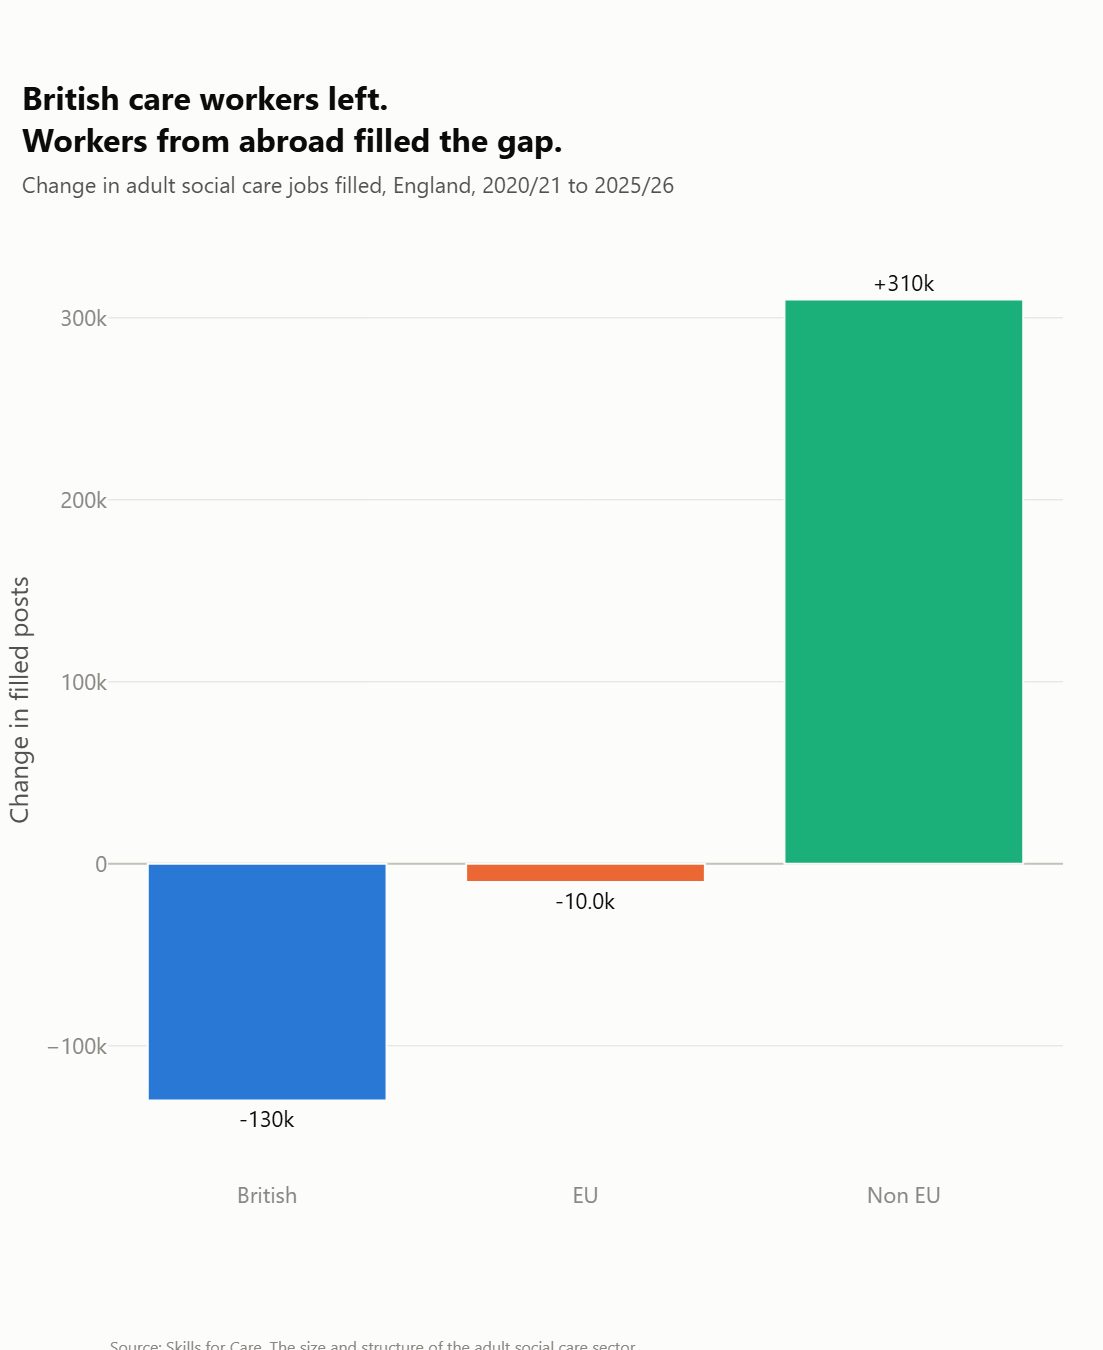

In [103]:
w = sfc.pivot(index="year_start", columns="measure", values="value")
change = (w.loc[2025] - w.loc[2020])[["filled_posts_british", "filled_posts_eu", "filled_posts_non_eu"]]
change.index = ["British", "EU", "Non EU"]

cdf = change.reset_index()
cdf.columns = ["Nationality", "Change"]

fig = px.bar(cdf, x="Nationality", y="Change", color="Nationality", text_auto="+.3s")
fig.update_layout(showlegend=False, xaxis_title="", yaxis_title="Change in filled posts")
fig.update_traces(textposition="outside")

finish(fig,
       title="British care workers left.<br>Workers from abroad filled the gap.",
       subtitle="Change in adult social care jobs filled, England, 2020/21 to 2025/26",
       source="Source: Skills for Care, The size and structure of the adult social care sector<br>"
              "and workforce in England 2026, Table 2.",
       name="03_care_workforce").show()

In [107]:
fees_path = "../data/manual/Fees_Table_08_October_26.ods"
print(pd.ExcelFile(fees_path, engine="odf").sheet_names)

['Fees_Table_08_Oct']


In [109]:
fees_raw = pd.read_excel(fees_path, engine="odf", sheet_name="Fees_Table_08_Oct", header=None)
print(fees_raw.shape)
fees_raw.head(15)

(201, 5)


,0,1,2,3,4
0,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN
3,Fees category,Current Fee,Fee from 08 October 2026,Fee Change,% Change
4,1. Visas - applications made outside the UK,NaN,NaN,NaN,NaN
5,Visit visa – short up to 6 months,135.0,135.0,0.0,0.0
6,Visit visa – long up to 2 years [Footnote 1],506.0,506.0,0.0,0.0
7,Visit visa – long up to 5 years,903.0,903.0,0.0,0.0
8,Visit visa – long up to 10 years,1128.0,1128.0,0.0,0.0
9,Visiting academic - more than 6 months but no more than 12 months,234.0,234.0,0.0,0.0


In [111]:
fees_tbl = pd.read_excel(fees_path, engine="odf", sheet_name="Fees_Table_08_Oct", skiprows=3)
fees_tbl.columns = ["Category", "Previous fee", "Fee", "Change", "Pct change"]

# Section headings are the rows with no fee
is_section = fees_tbl["Fee"].isna()
fees_tbl["Section"] = fees_tbl["Category"].where(is_section).ffill()
fees_tbl = fees_tbl[~is_section].copy()

# Remove footnote markers like "[Footnote 1]" from the names
fees_tbl["Category"] = fees_tbl["Category"].str.replace(r"\s*\[Footnote.*?\]", "", regex=True).str.strip()

fees_tbl[["Section", "Category", "Fee"]].head(10)

,Section,Category,Fee
1,1. Visas - applications made outside the UK,Visit visa – short up to 6 months,135.0
2,1. Visas - applications made outside the UK,Visit visa – long up to 2 years,506.0
3,1. Visas - applications made outside the UK,Visit visa – long up to 5 years,903.0
4,1. Visas - applications made outside the UK,Visit visa – long up to 10 years,1128.0
5,1. Visas - applications made outside the UK,Visiting academic - more than 6 months but no more than 12 months,234.0
6,1. Visas - applications made outside the UK,Private medical treatment visa - more than 6 months but not more than 11 months,234.0
7,1. Visas - applications made outside the UK,Transit visa - (direct airside transit),41.5
8,1. Visas - applications made outside the UK,Transit visit visa - (landside transit),74.5
9,1. Visas - applications made outside the UK,Visa for the purpose of joining a ship or aircraft as a member of the crew of that ship or aircraft,74.5
10,1. Visas - applications made outside the UK,Single-entry visa to replace a Biometric Residence Permit (BRP),154.0


In [113]:
def find(word):
    return fees_tbl[fees_tbl["Category"].str.contains(word, case=False, na=False)][["Section", "Category", "Fee"]]

find("Graduate")

,Section,Category,Fee
53,2. Work - applications made outside the UK,Global Business Mobility – Graduate Trainee - main applicant and dependants,340.0
101,7. Work - applications made in the UK,Graduate Route – main applicant and dependants,937.0
119,7. Work - applications made in the UK,Global Business Mobility – Graduate Trainee - main applicant and dependants,340.0
183,11. Sponsorship,"Certificate of Sponsorship (CoS), or approval under Sponsor a Worker:- Temporary Worker including Global Business Mobility - Graduate Trainee, UK expansion Worker, Service Supplier and Secondment Worker route and Scale-up route",55.0


In [115]:
def get_fee(section_has, category_has):
    match = fees_tbl[
        fees_tbl["Section"].str.contains(section_has, case=False, na=False)
        & fees_tbl["Category"].str.contains(category_has, case=False, na=False, regex=False)
    ]
    if len(match) != 1:
        raise ValueError(f"Expected 1 match for '{category_has}' in '{section_has}', found {len(match)}:\n"
                         f"{match[['Section', 'Category', 'Fee']]}")
    return match["Fee"].iloc[0]

get_fee("Work - applications made in the UK", "Graduate Route")

937.0

In [117]:
for w in ["Student", "Skilled Worker", "Indefinite", "Naturalisation", "ceremony", "Life in the UK"]:
    display(find(w))

,Section,Category,Fee
61,3. Study - applications made outside the UK,Student - main applicant and dependants,558.0
62,3. Study - applications made outside the UK,Child Student,558.0
63,3. Study - applications made outside the UK,Short term student studying English language for more than 6 months but not more than 11 months,228.0
127,8. Study - applications made in the UK,Student - main applicant and dependants,558.0
128,8. Study - applications made in the UK,Child Student,558.0
168,11. Sponsorship,"The expedited processing of a sponsorship management request made by a Worker sponsor, a Temporary worker sponsor or a student sponsor",350.0
172,11. Sponsorship,Student sponsor licence,611.0
175,11. Sponsorship,Worker and Student sponsor licence (large sponsor),1682.0
176,11. Sponsorship,"Worker, Temporary Worker and Student sponsor licence (large sponsor)",1682.0
177,11. Sponsorship,Temporary Worker and Student sponsor licence,611.0


,Section,Category,Fee
38,2. Work - applications made outside the UK,"Skilled Worker, where a certificate of sponsorship has been issued or approval to sponsor under Sponsor a Worker has been given for three years or less - main applicant and dependants",819.0
39,2. Work - applications made outside the UK,"Skilled Worker, where a certificate of sponsorship has been issued or approval to sponsor under Sponsor a Worker has been given for over three years - main applicant and dependants",1618.0
40,2. Work - applications made outside the UK,Skilled Worker - a job on the Immigration Salary List where a certificate of sponsorship has been issued or approval to sponsor under Sponsor a Worker has been given for three years or less - main applicant and dependants,628.0
41,2. Work - applications made outside the UK,Skilled Worker - a job on the Immigration Salary List where a certificate of sponsorship has been issued or approval to sponsor under Sponsor a Worker has been given for over three years - main applicant and dependants,1235.0
42,2. Work - applications made outside the UK,Skilled Worker - Health and Care Visa - where a certificate of sponsorship has been issued or approval to sponsor under Sponor a Worker has been given for three years or less - main applicant and dependants,324.0
43,2. Work - applications made outside the UK,Skilled Worker - Health and Care Visa - where a certificate of sponsorship has been issued or approval to sponsor under Sponsor a Worker has been given for over three years - main applicant and dependants,628.0
44,2. Work - applications made outside the UK,Skilled Worker - a job on the Immigration Salary List - Health and Care Visa - where a certificate of sponsorship has been issued or approval to sponsor under Sponsor a Worker has been given for three years or less - main applicant and dependants,324.0
45,2. Work - applications made outside the UK,Skilled Worker - a job on the Immigration Salary List - Health and Care Visa - where a certificate of sponsorship has been issued or approval to sponsor under Sponsor a Worker has been given for over three years - main applicant and dependants,628.0
104,7. Work - applications made in the UK,"Skilled Worker, where a certificate of sponsorship has been issued or approval to sponsor under Sponsor a Worker has been given for three years or less - main applicant and dependants",943.0
105,7. Work - applications made in the UK,"Skilled Worker, where a certificate of sponsorship has been issued or approval to sponsor under Sponsor a Worker has been given for over three years - main applicant and dependants",1865.0


,Section,Category,Fee
19,1. Visas - applications made outside the UK,Indefinite leave to enter the UK as the dependant of an HM Armed Forces service leaver or a member of HM Armed Forces under Appendix HM Armed Forces to the Immigration Rules,3226.0
20,1. Visas - applications made outside the UK,Indefinite leave to enter the UK as an HM Armed Forces service leaver or a member of HM Armed Forces under Appendix HM Armed Forces to the Immigration Rules,3226.0
25,1. Visas - applications made outside the UK,Indefinite leave to enter the UK as a victim of domestic abuse and dependent children under Appendix Victim of Domestic Abuse to the Immigration Rules,3226.0
137,9. Other applications made in the UK,Indefinite leave to remain - main applicant and dependants,3226.0


,Section,Category,Fee
148,10. Nationality,Naturalisation (British citizenship),1709.0
149,10. Nationality,Naturalisation British overseas territory citizens,1140.0


,Section,Category,Fee
154,10. Nationality,The arrangement of a citizenship ceremony (including the administration of a citizenship oath and pledge at the ceremony).,130.0
155,10. Nationality,"The administration of a citizenship oath, or oath and pledge where the oath, or oath and pledge, are not administered at a citizenship ceremony or by a justice of the peace.",5.0


,Section,Category,Fee
145,9. Other applications made in the UK,Life in the UK test,50.0


In [119]:
def get_fee(section_has, *words):
    mask = fees_tbl["Section"].str.contains(section_has, case=False, na=False)
    for w in words:
        mask &= fees_tbl["Category"].str.contains(w, case=False, na=False, regex=False)
    match = fees_tbl[mask]
    if len(match) != 1:
        raise ValueError(f"Expected 1 match for {words} in '{section_has}', found {len(match)}:\n"
                         f"{match[['Section', 'Category', 'Fee']]}")
    return match["Fee"].iloc[0]

In [121]:
row = fees_tbl[fees_tbl["Category"].str.contains("Naturalisation", na=False)]
for name in row["Category"]:
    print(repr(name))

'Naturalisation\xa0(British citizenship)'
'Naturalisation British overseas territory citizens'


In [123]:
fees_tbl["Category"] = fees_tbl["Category"].str.replace(r"\s+", " ", regex=True).str.strip()

In [125]:
fees_tbl["Section"] = fees_tbl["Section"].str.replace(r"\s+", " ", regex=True).str.strip()

In [127]:
in_uk_work = "Work - applications made in the UK"

fees = {
    "student_visa": get_fee("Study - applications made outside the UK", "Student - main applicant"),
    "graduate_visa": get_fee(in_uk_work, "Graduate Route"),
    "skilled_worker_up_to_3y_in_uk": get_fee(in_uk_work, "Skilled Worker, where", "three years or less"),
    "skilled_worker_over_3y_in_uk": get_fee(in_uk_work, "Skilled Worker, where", "over three years"),
    "ilr": get_fee("Other applications made in the UK", "Indefinite leave to remain"),
    "life_in_uk_test": get_fee("Other applications made in the UK", "Life in the UK test"),
    "naturalisation_adult": get_fee("Nationality", "Naturalisation (British citizenship)"),
    "citizenship_ceremony": get_fee("Nationality", "arrangement of a citizenship ceremony"),
}

# The health surcharge isn't in the fee table. Source: gov.uk Immigration Health Surcharge,
# unchanged since 6 February 2024. Check https://www.gov.uk/healthcare-immigration-application/how-much-pay
fees["ihs_standard"] = 1035
fees["ihs_student_child"] = 776

fees

{'student_visa': 558.0,
 'graduate_visa': 937.0,
 'skilled_worker_up_to_3y_in_uk': 943.0,
 'skilled_worker_over_3y_in_uk': 1865.0,
 'ilr': 3226.0,
 'life_in_uk_test': 50.0,
 'naturalisation_adult': 1709.0,
 'citizenship_ceremony': 130.0,
 'ihs_standard': 1035,
 'ihs_student_child': 776}

In [129]:
def journey(sw_years):
    steps = [
        ("Student visa", fees["student_visa"], fees["ihs_student_child"] * 1.5),
        ("Graduate visa", fees["graduate_visa"], fees["ihs_standard"] * 2),
    ]
    # Skilled Worker visas, in chunks of up to 3 years
    remaining, n = sw_years, 1
    while remaining > 0:
        y = min(3, remaining)
        steps.append((f"Skilled Worker visa {n} ({y} years)",
                      fees["skilled_worker_up_to_3y_in_uk"], fees["ihs_standard"] * y))
        remaining -= y
        n += 1
    steps.append(("ILR + Life in the UK test", fees["ilr"] + fees["life_in_uk_test"], 0))
    steps.append(("Citizenship", fees["naturalisation_adult"] + fees["citizenship_ceremony"], 0))

    df = pd.DataFrame(steps, columns=["Step", "Application fees", "Health surcharge"])
    df["Step total"] = df["Application fees"] + df["Health surcharge"]
    df["Running total"] = df["Step total"].cumsum()
    return df

journey(5)

,Step,Application fees,Health surcharge,Step total,Running total
0,Student visa,558.0,1164.0,1722.0,1722.0
1,Graduate visa,937.0,2070.0,3007.0,4729.0
2,Skilled Worker visa 1 (3 years),943.0,3105.0,4048.0,8777.0
3,Skilled Worker visa 2 (2 years),943.0,2070.0,3013.0,11790.0
4,ILR + Life in the UK test,3276.0,0.0,3276.0,15066.0
5,Citizenship,1839.0,0.0,1839.0,16905.0


In [133]:
scenarios = {
    "Current rules (5 years on Skilled Worker)": 5,
    "10 year rule, if study and Graduate years count": 7,
    "10 year rule, if only Skilled Worker years count": 10,
}
totals = pd.DataFrame(
    [{"Scenario": name, "Total cost": journey(y)["Step total"].sum()} for name, y in scenarios.items()]
)
totals

,Scenario,Total cost
0,Current rules (5 years on Skilled Worker),16905.0
1,"10 year rule, if study and Graduate years count",19918.0
2,"10 year rule, if only Skilled Worker years count",23966.0


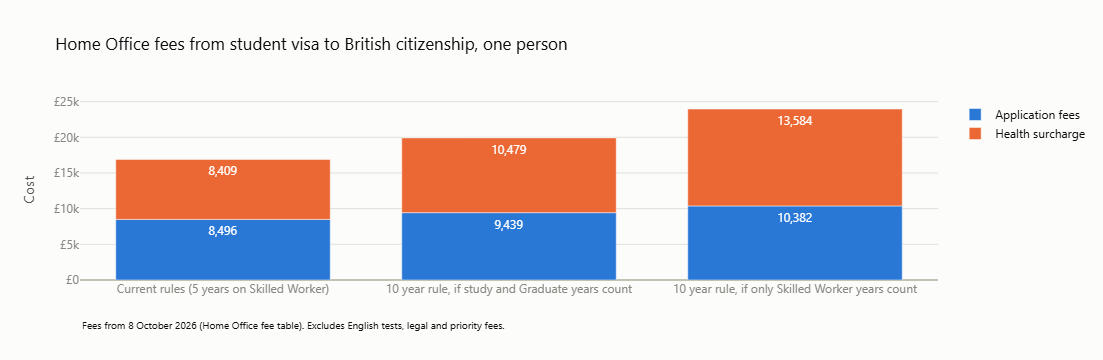

In [135]:
rows = []
for name, y in scenarios.items():
    j = journey(y)
    rows.append({"Scenario": name, "Part": "Application fees", "Cost": j["Application fees"].sum()})
    rows.append({"Scenario": name, "Part": "Health surcharge", "Cost": j["Health surcharge"].sum()})
stack = pd.DataFrame(rows)

fig = px.bar(stack, x="Scenario", y="Cost", color="Part", text_auto=",.0f",
             title="Home Office fees from student visa to British citizenship, one person")
fig.update_layout(yaxis_tickprefix="£", xaxis_title="", legend_title="")
fig.add_annotation(text="Fees from 8 October 2026 (Home Office fee table). Excludes English tests, legal and priority fees.",
                   xref="paper", yref="paper", x=0, y=-0.3, showarrow=False, font_size=10)
fig.show()

In [137]:
fees["skilled_worker_up_to_3y_outside_uk"] = get_fee(
    "Work - applications made outside the UK", "Skilled Worker, where", "three years or less")

display(find("child")[lambda d: d["Section"].str.contains("Nationality")])

,Section,Category,Fee
151,10. Nationality,Nationality registration as a British citizen - child,1000.0
153,10. Nationality,Nationality Registration as a British citizen (under provisions for Irish citizens) - child,607.0
157,10. Nationality,"Nationality registration - British overseas territory citizen, British overseas citizens, British Subjects, British protected persons - child",863.0


In [139]:
fees["child_registration"] = get_fee("Nationality", "British citizen - child")

In [141]:
def family_journey(sw_years, adults=2, children=2):
    people = adults + children
    ihs_per_year = adults * fees["ihs_standard"] + children * fees["ihs_student_child"]
    steps = []
    remaining, n = sw_years, 1
    while remaining > 0:
        y = min(3, remaining)
        fee = fees["skilled_worker_up_to_3y_outside_uk"] if n == 1 else fees["skilled_worker_up_to_3y_in_uk"]
        steps.append((f"Skilled Worker visa {n} ({y} years)", fee * people, ihs_per_year * y))
        remaining -= y
        n += 1
    steps.append(("ILR (whole family)", fees["ilr"] * people + fees["life_in_uk_test"] * adults, 0))
    steps.append(("Citizenship (whole family)",
                  (fees["naturalisation_adult"] + fees["citizenship_ceremony"]) * adults
                  + fees["child_registration"] * children, 0))

    df = pd.DataFrame(steps, columns=["Step", "Application fees", "Health surcharge"])
    df["Step total"] = df["Application fees"] + df["Health surcharge"]
    df["Running total"] = df["Step total"].cumsum()
    return df

print(family_journey(5)["Step total"].sum(), family_journey(10)["Step total"].sum())

43840.0 69494.0


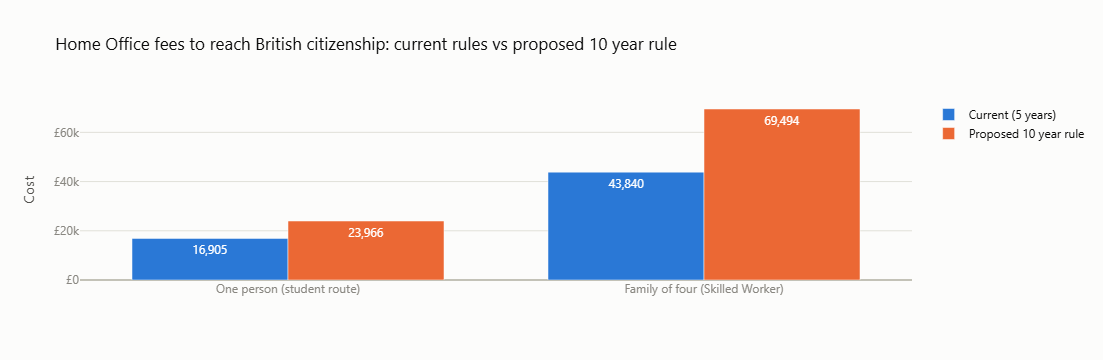

In [143]:
compare = pd.DataFrame([
    {"Who": "One person (student route)", "Rules": "Current (5 years)", "Cost": journey(5)["Step total"].sum()},
    {"Who": "One person (student route)", "Rules": "Proposed 10 year rule", "Cost": journey(10)["Step total"].sum()},
    {"Who": "Family of four (Skilled Worker)", "Rules": "Current (5 years)", "Cost": family_journey(5)["Step total"].sum()},
    {"Who": "Family of four (Skilled Worker)", "Rules": "Proposed 10 year rule", "Cost": family_journey(10)["Step total"].sum()},
])

fig = px.bar(compare, x="Who", y="Cost", color="Rules", barmode="group", text_auto=",.0f",
             title="Home Office fees to reach British citizenship: current rules vs proposed 10 year rule")
fig.update_layout(yaxis_tickprefix="£", xaxis_title="", legend_title="")
fig.show()

In [145]:
se_path = "../data/raw/settlement-datasets-jun-2026.xlsx"
print(pd.ExcelFile(se_path).sheet_names)

['Cover_sheet', 'Contents', 'Notes_and_Definitions', 'List of fields', 'Se_D01', 'Data_Se_D01', 'Se_D02', 'Data_Se_D02', 'Se_D03', 'Data_Se_D03']


In [147]:
se_raw = pd.read_excel(se_path, sheet_name="Data_Se_D02", header=None)
se_raw.head(10)

,0,1,2,3,4,5,6,7,8
0,"Se_D02: Grants of settlement by category, nationality, type of applicant and in-country refusals of settlement, 2020 to Q2 2026 - dataset",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Year,Quarter,Outcome,Nationality,Region,Applicant type,Category of leave group,Category of leave,Decisions
2,2020,2020 Q1,Grant,Afghanistan,Asia Central,All,Family,Children,127
3,2020,2020 Q1,Grant,Afghanistan,Asia Central,All,Family,Other and unspecified dependants,7
4,2020,2020 Q1,Grant,Afghanistan,Asia Central,All,Other,Other grants,10
5,2020,2020 Q1,Grant,Afghanistan,Asia Central,Dependant,Work,High value,21
6,2020,2020 Q1,Grant,Afghanistan,Asia Central,All,Family,Spouse/Partner,132
7,2020,2020 Q1,Grant,Afghanistan,Asia Central,Main applicant,Refugee,"Refugees and persons given ELR, HP or DL",216
8,2020,2020 Q1,Grant,Afghanistan,Asia Central,Main applicant,Work,High value,2
9,2020,2020 Q1,Grant,Afghanistan,Asia Central,Main applicant,Work,Skilled Worker,1


In [148]:
se = pd.read_excel(se_path, sheet_name="Data_Se_D02", skiprows=1)
se.dtypes

Year                        int64
Quarter                    object
Outcome                    object
Nationality                object
Region                     object
Applicant type             object
Category of leave group    object
Category of leave          object
Decisions                   int64
dtype: object

In [149]:
for col in ["Outcome", "Applicant type", "Category of leave group", "Category of leave"]:
    print(col, se[col].unique(), "\n")

Outcome ['Grant' 'Refusal'] 

Applicant type ['All' 'Dependant' 'Main applicant' 'Refusal'] 

Category of leave group ['Family' 'Other' 'Work' 'Refugee' 'Refusal'] 

Category of leave ['Children' 'Other and unspecified dependants' 'Other grants' 'High value'
 'Spouse/Partner' 'Refugees and persons given ELR, HP or DL'
 'Skilled Worker' 'Refusal' 'UK Ancestry' 'Family Life'
 'Permit-free employment, businessperson, persons of independent means'
 'Work - Other' 'ECAA' 'Work Permit Holders' 'BN(O) Route' 'Private Life'] 



In [151]:
grants.columns

Index(['Year', 'Quarter', 'Nationality', 'Region', 'Visa type group',
       'Visa type', 'Visa type subgroup', 'Applicant type', 'Case outcome',
       'Decisions'],
      dtype='object')

In [155]:
grants = se[(se["Outcome"] == "Grant") & (se["Year"] <= 2025)]

by_group = (
    grants.groupby(["Year", "Category of leave group"])["Decisions "]
    .sum()
    .unstack()
)
by_group["Total"] = by_group.sum(axis=1)
by_group

Category of leave group,Family,Other,Refugee,Work,Total
Year,,,,,
2020,31659,8849,23343,25802,89653
2021,39928,14368,23271,31449,109016
2022,35084,12275,52132,31775,131266
2023,34197,13111,28538,42626,118472
2024,47672,17272,37887,56963,159794
2025,36392,20199,26486,63042,146119


In [157]:
work = (
    grants[grants["Category of leave group"] == "Work"]
    .groupby(["Year", "Category of leave"])["Decisions "]
    .sum()
    .unstack(fill_value=0)
)
work

Category of leave,ECAA,High value,"Permit-free employment, businessperson, persons of independent means",Skilled Worker,UK Ancestry,Work - Other,Work Permit Holders
Year,,,,,,,
2020,680,4039,289,18607,2182,4,1
2021,1006,3299,258,24214,2667,4,1
2022,2209,3056,156,23839,2506,8,1
2023,3575,4830,419,30447,3340,15,0
2024,3334,5516,366,44130,3615,1,1
2025,6256,6196,361,47489,2735,5,0


In [159]:
ref22 = grants[(grants["Year"] == 2022) & (grants["Category of leave group"] == "Refugee")]
ref22.groupby("Nationality")["Decisions "].sum().nlargest(5)

Nationality
Afghanistan    15479
Syria           9536
Eritrea         5191
Iran            5044
Sudan           2337
Name: Decisions , dtype: int64

In [161]:
  grants[grants["Category of leave group"] == "Other"].groupby(["Year", "Category of leave"])["Decisions "].sum().unstack(fill_value=0)

Category of leave,BN(O) Route,Other grants,Private Life
Year,,,
2020,0,8849,0
2021,4,14364,0
2022,55,12106,114
2023,259,11332,1520
2024,632,13983,2657
2025,670,15970,3559


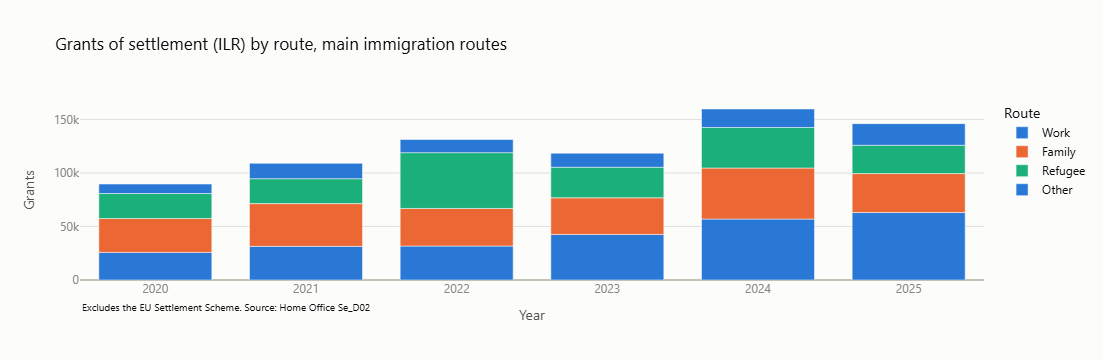

In [163]:
category_orders={"Route": ["Work", "Family", "Refugee", "Other"]}
fig = px.bar(by_group.drop(columns="Total",).reset_index().melt(id_vars="Year", var_name="Route", value_name="Grants"),
             x="Year", y="Grants", color="Route",category_orders=category_orders,
             title="Grants of settlement (ILR) by route, main immigration routes")
fig.update_xaxes(dtick=1)
fig.add_annotation(text="Excludes the EU Settlement Scheme. Source: Home Office Se_D02",
                   xref="paper", yref="paper", x=0, y=-0.2, showarrow=False, font_size=10)
fig.show()

In [165]:
grants[(grants["Category of leave group"] == "Refugee") & (grants["Nationality"] == "Afghanistan")].groupby("Year")["Decisions "].sum()

Year
2020     1402
2021     1350
2022    15479
2023     2238
2024     2495
2025     1931
Name: Decisions , dtype: int64

In [167]:
print(mj[mj["Initial leave type group"] == "Work"]["Initial leave subgroup"].unique())
print(mj[mj["Initial leave type"] == "BN(O) route"]["Initial leave subgroup"].unique())

['Investor, business development and talent'
 'Other work visas and exemptions' 'Temporary Worker' 'Tier 2 - General'
 'Worker (Other)' 'Health and Care Worker' 'Skilled Worker']
['BN(O) route']


In [171]:
def stay_rates(subgroups):
    d = mj[mj["Initial leave subgroup"].isin(subgroups)]
    t = (
        d.groupby(["Year of initial leave", "Years since start",
                   "Immigration Status at end of year"])["Journeys"]
        .sum()
        .unstack(fill_value=0)
    )
    total = t.sum(axis=1)
    t["Still here %"] = (t["Valid leave to remain"] + t["Indefinite leave to remain"]) / total * 100
    return t["Still here %"].unstack("Years since start").round(1)

display(stay_rates(["Tier 2 - General"]))
display(stay_rates(["Skilled Worker"]))
display(stay_rates(["Health and Care Worker"]))
display(stay_rates(["BN(O) route"]))

Years since start,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
Year of initial leave,,,,,,,,,,,,,,,,,,
2008,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2009,93.7,86.9,78.5,56.3,51.4,48.8,45.8,44.7,44.1,43.9,43.6,43.5,43.5,43.4,43.4,43.3,43.3,NaN
2010,95.7,90.6,83.4,62.5,59.7,57.7,54.3,53.5,53.1,52.9,52.7,52.6,52.6,52.6,52.5,52.4,NaN,NaN
2011,98.1,92.9,86.3,62.1,58.6,56.0,50.2,49.3,49.0,48.7,48.7,48.6,48.5,48.5,48.5,NaN,NaN,NaN
2012,97.0,92.7,85.4,58.4,54.6,51.9,46.2,45.6,45.1,45.0,44.8,44.7,44.7,44.7,NaN,NaN,NaN,NaN
2013,99.3,95.9,89.1,63.7,59.8,56.8,50.9,50.3,50.0,49.6,49.4,49.3,49.2,NaN,NaN,NaN,NaN,NaN
2014,99.3,96.6,91.2,72.4,69.3,61.2,56.5,56.0,55.7,55.5,55.4,55.3,NaN,NaN,NaN,NaN,NaN,NaN
2015,99.6,97.0,92.3,77.5,74.6,64.3,60.6,60.2,60.0,59.8,59.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016,99.5,97.4,92.7,79.1,76.7,68.0,64.6,64.2,63.8,63.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Years since start,0,1,2,3,4,5
Year of initial leave,,,,,,
2020,100.0,99.3,96.5,90.1,84.5,83.1
2021,99.6,97.4,94.1,83.9,81.2,NaN
2022,99.6,97.0,93.6,82.1,NaN,NaN
2023,99.3,96.0,91.4,NaN,NaN,NaN
2024,99.2,94.6,NaN,NaN,NaN,NaN
2025,98.2,NaN,NaN,NaN,NaN,NaN


Years since start,0,1,2,3,4,5
Year of initial leave,,,,,,
2020,100.0,100.0,99.5,97.4,94.1,91.5
2021,99.9,98.8,97.0,91.0,89.1,NaN
2022,99.9,99.1,97.2,92.1,NaN,NaN
2023,99.9,99.0,96.8,NaN,NaN,NaN
2024,99.6,97.4,NaN,NaN,NaN,NaN
2025,99.2,NaN,NaN,NaN,NaN,NaN


Years since start,0,1,2,3,4
Year of initial leave,,,,,
2021,99.9,99.9,99.4,98.2,98.2
2022,100.0,100.0,98.5,97.5,NaN
2023,100.0,100.0,98.3,NaN,NaN
2024,100.0,100.0,NaN,NaN,NaN
2025,100.0,NaN,NaN,NaN,NaN


In [173]:
vis = pd.read_parquet("../data/processed/vis_d02.parquet")
vg = vis[(vis["Case outcome"] == "Issued") & (vis["Visa type group"] != "Visitor")]

In [175]:
vg.to_parquet("../data/processed/visa_grants.parquet")

In [177]:
stay = {"Skilled Worker": 0.83, "Health and Care Worker": 0.915, "BN(O)": 0.98}
routes = {
    "Skilled Worker": vg["Visa type subgroup"] == "Skilled Worker",
    "Health and Care Worker": vg["Visa type subgroup"] == "Health and Care Worker",
    "BN(O)": vg["Visa type"] == "BN(O) route",
}

rows = []
for route, mask in routes.items():
    arrivals = vg[mask & vg["Year"].between(2021, 2025)].groupby("Year")["Decisions"].sum()
    for year, n in arrivals.items():
        rows.append({"Route": route, "Arrived": year, "Arrivals": n,
                     "Still here": round(n * stay[route])})

model = pd.DataFrame(rows)
model["Eligible, 5 year rule"] = model["Arrived"] + 5
model["Eligible, 10 year rule"] = model["Arrived"] + 10
model

,Route,Arrived,Arrivals,Still here,"Eligible, 5 year rule","Eligible, 10 year rule"
0,Skilled Worker,2021,59296,49216,2026,2031
1,Skilled Worker,2022,112139,93075,2027,2032
2,Skilled Worker,2023,117180,97259,2028,2033
3,Skilled Worker,2024,115012,95460,2029,2034
4,Skilled Worker,2025,73066,60645,2030,2035
5,Health and Care Worker,2021,63291,57911,2026,2031
6,Health and Care Worker,2022,157636,144237,2027,2032
7,Health and Care Worker,2023,348157,318564,2028,2033
8,Health and Care Worker,2024,110473,101083,2029,2034
9,Health and Care Worker,2025,48532,44407,2030,2035


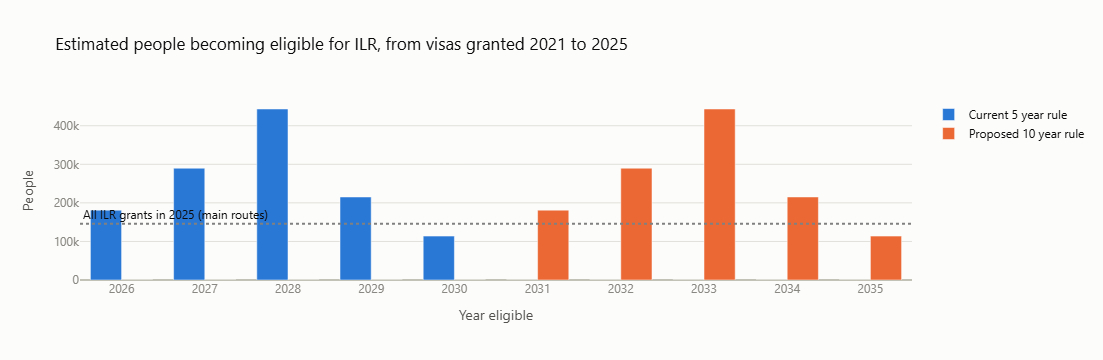

In [179]:
current = model.groupby("Eligible, 5 year rule")["Still here"].sum()
proposed = model.groupby("Eligible, 10 year rule")["Still here"].sum()

proj = pd.DataFrame({"Current 5 year rule": current, "Proposed 10 year rule": proposed}).fillna(0)
proj = proj.reindex(range(2026, 2036), fill_value=0)

fig = px.bar(proj, barmode="group",
             title="Estimated people becoming eligible for ILR, from visas granted 2021 to 2025")
fig.update_layout(xaxis_title="Year eligible", yaxis_title="People", legend_title="")
fig.add_hline(y=146119, line_dash="dot", line_color="grey",
              annotation_text="All ILR grants in 2025 (main routes)", annotation_position="top left")
fig.update_xaxes(dtick=1)
fig.show()

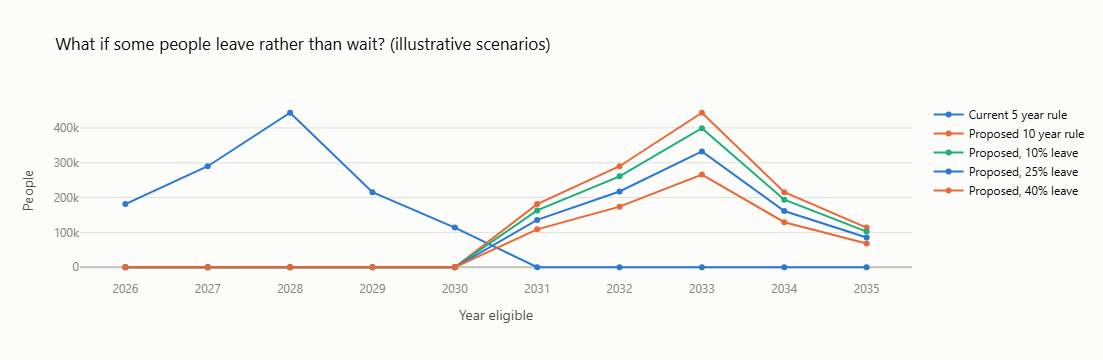

Current 5 year rule      1244000.0
Proposed 10 year rule    1244000.0
Proposed, 10% leave      1119000.0
Proposed, 25% leave       933000.0
Proposed, 40% leave       746000.0
dtype: float64

In [181]:
for leave in [0.10, 0.25, 0.40]:
    proj[f"Proposed, {int(leave*100)}% leave"] = proj["Proposed 10 year rule"] * (1 - leave)

fig = px.line(proj, markers=True,
              title="What if some people leave rather than wait? (illustrative scenarios)")
fig.update_layout(xaxis_title="Year eligible", yaxis_title="People", legend_title="")
fig.update_xaxes(dtick=1)
fig.show()

proj.sum().round(-3)

In [183]:
hc_occ = occ[(occ["Visa type subgroup"] == "Health and Care Worker") & occ["Year"].between(2021, 2025)]

care_share = (
    hc_occ[hc_occ["Occ. minor group"].str.startswith("613")].groupby("Year")["Grants"].sum()
    / hc_occ.groupby("Year")["Grants"].sum()
)
care_share.round(2)

Year
2021    0.11
2022    0.49
2023    0.74
2024    0.35
2025    0.24
Name: Grants, dtype: float64

In [185]:
wait = {"Skilled Worker": 10, "Health workers": 5, "Care workers": 15, "BN(O)": 5}

rows = []
for route, mask in routes.items():
    arrivals = vg[mask & vg["Year"].between(2021, 2025)].groupby("Year")["Decisions"].sum()
    for year, n in arrivals.items():
        still = n * stay[route]
        if route == "Health and Care Worker":
            parts = {"Care workers": still * care_share[year],
                     "Health workers": still * (1 - care_share[year])}
        else:
            parts = {route: still}
        for name, people in parts.items():
            rows.append({"Route": name, "Arrived": year, "Still here": round(people),
                         "Eligible, current rules": year + 5,
                         "Eligible, proposed rules": year + wait[name]})

model = pd.DataFrame(rows)
model

,Route,Arrived,Still here,"Eligible, current rules","Eligible, proposed rules"
0,Skilled Worker,2021,49216,2026,2031
1,Skilled Worker,2022,93075,2027,2032
2,Skilled Worker,2023,97259,2028,2033
3,Skilled Worker,2024,95460,2029,2034
4,Skilled Worker,2025,60645,2030,2035
5,Care workers,2021,6269,2026,2036
6,Health workers,2021,51643,2026,2026
7,Care workers,2022,70294,2027,2037
8,Health workers,2022,73943,2027,2027
9,Care workers,2023,237227,2028,2038


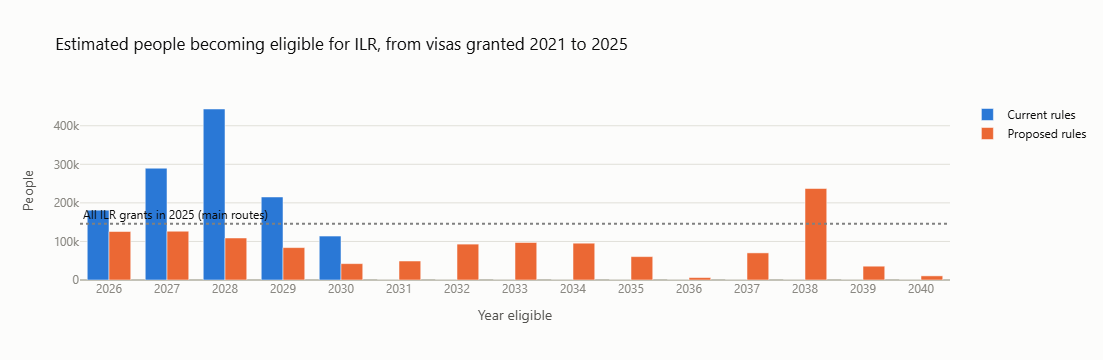

In [187]:
current = model.groupby("Eligible, current rules")["Still here"].sum()
proposed = model.groupby("Eligible, proposed rules")["Still here"].sum()

proj = pd.DataFrame({"Current rules": current, "Proposed rules": proposed}).fillna(0)
proj = proj.reindex(range(2026, 2041), fill_value=0)

fig = px.bar(proj, barmode="group",
             title="Estimated people becoming eligible for ILR, from visas granted 2021 to 2025")
fig.add_hline(y=146119, line_dash="dot", line_color="grey",
              annotation_text="All ILR grants in 2025 (main routes)", annotation_position="top left")
fig.update_layout(xaxis_title="Year eligible", yaxis_title="People", legend_title="")
fig.update_xaxes(dtick=1)
fig.show()